Calculated Otsu Threshold: 99


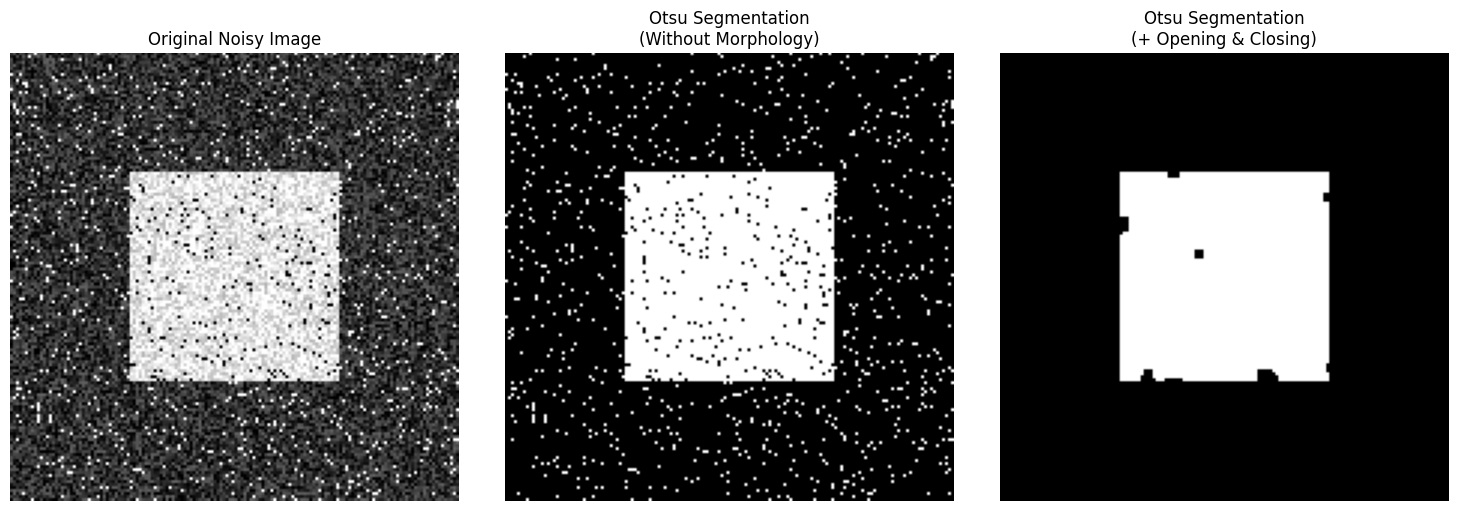

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def otsu_threshold(image):
    """Segment an image using Otsu's Thresholding from scratch."""
    pixel_counts, _ = np.histogram(image.ravel(), bins=256, range=(0, 256))
    total_pixels = image.size

    current_max_variance = 0
    best_threshold = 0

    sum_total = np.sum(np.arange(256) * pixel_counts)
    sum_background = 0
    weight_background = 0

    for t in range(256):
        weight_background += pixel_counts[t]
        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break

        sum_background += t * pixel_counts[t]

        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground

        variance_between = weight_background * weight_foreground * (mean_background - mean_foreground) ** 2

        if variance_between > current_max_variance:
            current_max_variance = variance_between
            best_threshold = t

    binary_image = (image > best_threshold).astype(np.uint8)
    return binary_image, best_threshold

def erosion(image, kernel):
    """Morphological Erosion from scratch."""
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=1)
    eroded = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            roi = padded[i:i+k_h, j:j+k_w]
            if np.all(roi[kernel == 1] == 1):
                eroded[i, j] = 1
    return eroded

def dilation(image, kernel):
    """Morphological Dilation from scratch."""
    k_h, k_w = kernel.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    dilated = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            roi = padded[i:i+k_h, j:j+k_w]
            if np.any(roi[kernel == 1] == 1):
                dilated[i, j] = 1
    return dilated

def opening(image, kernel):
    """Erosion followed by Dilation (Removes external salt noise)."""
    return dilation(erosion(image, kernel), kernel)

def closing(image, kernel):
    """Dilation followed by Erosion (Fills internal pepper noise/holes)."""
    return erosion(dilation(image, kernel), kernel)

np.random.seed(42)
original_img = np.zeros((150, 150))
original_img[40:110, 40:110] = 180

background_noise = np.random.randint(0, 100, (150, 150))
original_img = np.clip(original_img + background_noise, 0, 255)

original_img[np.random.rand(*original_img.shape) < 0.05] = 255
original_img[np.random.rand(*original_img.shape) < 0.05] = 0
original_img = original_img.astype(np.uint8)

segmented_img, threshold_val = otsu_threshold(original_img)
print(f"Calculated Otsu Threshold: {threshold_val}")

kernel = np.ones((3, 3), dtype=np.uint8)

cleaned_img = opening(segmented_img, kernel)
cleaned_img = closing(cleaned_img, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original Noisy Image")
plt.imshow(original_img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Otsu Segmentation\n(Without Morphology)")
plt.imshow(segmented_img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Otsu Segmentation\n(+ Opening & Closing)")
plt.imshow(cleaned_img, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()